Start comparing

In [ ]:
import pandas as pd

# Load the ground truth and prediction data
ground_truth = pd.read_csv('../../data/annotations/ground_truth_labels.csv')




In [ ]:

selected_columns = [
    '1_Link1',
    '1_Value1_Self_Direction_Thought_values',
    '1_Value1_Self_Direction_Action_values',
    '1_Value1_Stimulation_values',
    '1_Value1_Hedonism_values',
    '1_Value1_Achievement_values',
    '1_Value1_Power_Resources_values',
    '1_Value1_Power_dominance_values',
    '1_Value1_Face_values',
    '1_Value1_Security_Personal_values',
    '1_Value1_Security_Social_values',
    '1_Value1_Conformity_Rules_values',
    '1_Value1_Conformity_Interpersonal_values',
    '1_Value1_Tradition_values',
    '1_Value1_Humility_values',
    '1_Value1_Benevolence_Dependability_values',
    '1_Value1_Benevolence_Care_values',
    '1_Value1_Universalism_Concern_values',
    '1_Value1_Universalism_Nature_values',
    '1_Value1_Universalism_Tolerance_values'
]

# Create a new DataFrame with only the selected columns
ground_truth = ground_truth[selected_columns]

In [ ]:
# turn the values to vectors by different resolutions
import pandas as pd
import numpy as np

# Define the function
def transform_values(df, resolution_score):
    # Define the mappings
    mappings = {
        'high': {'present': 1, np.nan: 0, 'dominant': 2, 'conflict': -1},
        'mid': {'present': 1, np.nan: 0, 'dominant': 1, 'conflict': -1},
        'low': {'present': 1, np.nan: 0, 'dominant': 1, 'conflict': 1}
    }

    # Ensure the resolution_score is valid
    if resolution_score not in mappings:
        raise ValueError("Invalid resolution score. Choose 'high', 'mid', or 'low'.")

    # Map values based on the resolution score
    df_transformed = df.replace(mappings[resolution_score])
    return df_transformed

resolution = 'mid'
ground_truth_transformed = transform_values(ground_truth, resolution)



<ipython-input-3-d4dce304b9d0>:19: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_transformed = df.replace(mappings[resolution_score])


In [ ]:
ground_truth_transformed

,1_Link1,1_Value1_Self_Direction_Thought_values,1_Value1_Self_Direction_Action_values,1_Value1_Stimulation_values,1_Value1_Hedonism_values,1_Value1_Achievement_values,1_Value1_Power_Resources_values,1_Value1_Power_dominance_values,1_Value1_Face_values,1_Value1_Security_Personal_values,1_Value1_Security_Social_values,1_Value1_Conformity_Rules_values,1_Value1_Conformity_Interpersonal_values,1_Value1_Tradition_values,1_Value1_Humility_values,1_Value1_Benevolence_Dependability_values,1_Value1_Benevolence_Care_values,1_Value1_Universalism_Concern_values,1_Value1_Universalism_Nature_values,1_Value1_Universalism_Tolerance_values
0,@alexkay_video_6783398367490854150,0,-1,0,0,0,0,0,0,0,0,-1,0,0,0,1,0,0.0,0,0
1,@alexkay_video_6807140917636648197,0,-1,0,0,1,0,-1,1,-1,0,0,1,0,-1,0,-1,0.0,0,0
2,@alexkay_video_6811970678024195334,0,1,1,0,0,0,1,0,-1,0,0,0,0,0,0,1,0.0,0,0
3,@alexkay_video_6905879944979631365,0,0,0,0,0,1,0,0,0,0,0,-1,1,0,0,1,0.0,0,0
4,@alexkay_video_6925220555478027525,0,1,0,0,1,1,0,0,0,0,0,-1,0,0,0,0,0.0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
885,@zeuz__video_7346995193024957727,1,0,0,0,1,0,0,0,0,0,0,0,0,0,-1,0,0.0,0,0
886,@zeuz__video_7347384674781646111,0,0,0,0,0,0,1,0,0,0,0,-1,0,0,0,-1,0.0,0,0
887,@zeuz__video_7347848700145700126,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0.0,0,0
888,@zeuz__video_7348138821680139551,0,0,0,0,1,0,1,0,0,0,0,-1,0,0,0,0,0.0,0,0


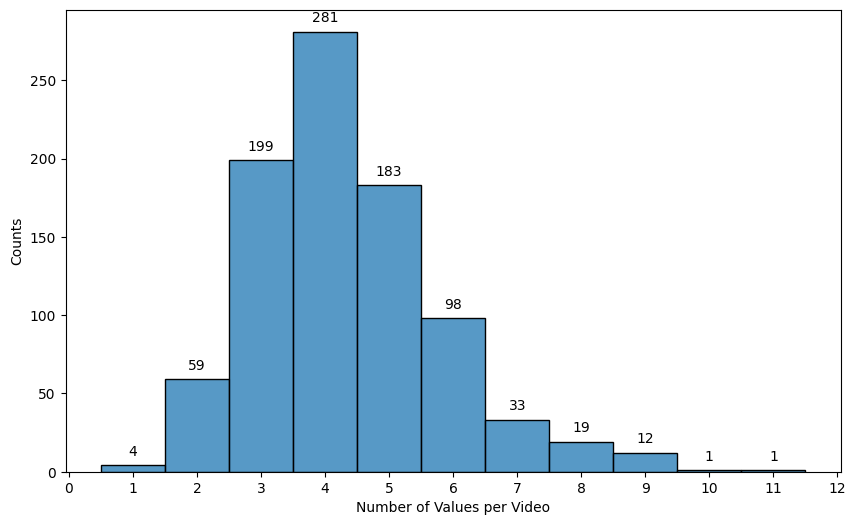

In [ ]:
# prompt: use 'ground_truth_transformed' to create a histogram whose x axis is number of values per video (no matter the value)
# and y axis is counts
# show all x axis tick from 0 to 12
# print all y values
# use seaborn

import seaborn as sns
import matplotlib.pyplot as plt

# Calculate the number of non-zero values per row (video)
value_counts_per_video = ground_truth_transformed.astype(bool).sum(axis=1)

# Create the histogram
plt.figure(figsize=(10, 6))
ax = sns.histplot(value_counts_per_video, discrete=True)

# Set the x-axis ticks and labels
ax.set_xticks(range(13))
ax.set_xlabel('Number of Values per Video')
ax.set_ylabel('Counts')
# plt.title('Distribution of Values per Video')
# Print y-axis values
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='center', xytext=(0, 10), textcoords='offset points')

plt.show()

In [ ]:
value_counts_per_video

,0
0,4
1,9
2,6
3,5
4,5
...,...
885,4
886,4
887,4
888,4


In [ ]:

df = ground_truth_transformed

# Exclude the 'id' column to focus on the class columns
class_columns = df.columns[1:]  # Assuming 'id' is the first column
n = len(class_columns)

# Initialize the co-occurrence matrix
co_occurrence_matrix = np.zeros((n, n))
co_occurrence_matrix_freq = np.zeros((n, n))
# Compute co-occurrence
for i in range(n):
    for j in range(n):
        if i != j:
            col_i = class_columns[i]
            col_j = class_columns[j]

            # Count co-occurrences
            count_neg_pos = ((df[col_i] == -1) & (df[col_j] == 1)).sum()
            count_pos_neg = ((df[col_i] == 1) & (df[col_j] == -1)).sum()
            count_neg_neg = ((df[col_i] == -1) & (df[col_j] == -1)).sum()
            count_pos_pos = ((df[col_i] == 1) & (df[col_j] == 1)).sum()

            # Store counts as needed (example: only -1/1 co-occurrence here)
            co_occurrence_matrix[i, j] = count_neg_pos

# Convert to DataFrame for better readability
co_occurrence_df = pd.DataFrame(co_occurrence_matrix,
                                columns=[f"Positive_{col}" for col in class_columns],
                                index=[f"Negative_{col}" for col in class_columns])

# Save or display the result
# co_occurrence_df.to_csv("co_occurrence_matrix.csv")
print(co_occurrence_df)


                                                    Positive_1_Value1_Self_Direction_Thought_values  \
Negative_1_Value1_Self_Direction_Thought_values                                                 0.0   
Negative_1_Value1_Self_Direction_Action_values                                                  5.0   
Negative_1_Value1_Stimulation_values                                                            3.0   
Negative_1_Value1_Hedonism_values                                                               0.0   
Negative_1_Value1_Achievement_values                                                            3.0   
Negative_1_Value1_Power_Resources_values                                                        2.0   
Negative_1_Value1_Power_dominance_values                                                        2.0   
Negative_1_Value1_Face_values                                                                  14.0   
Negative_1_Value1_Security_Personal_values                               

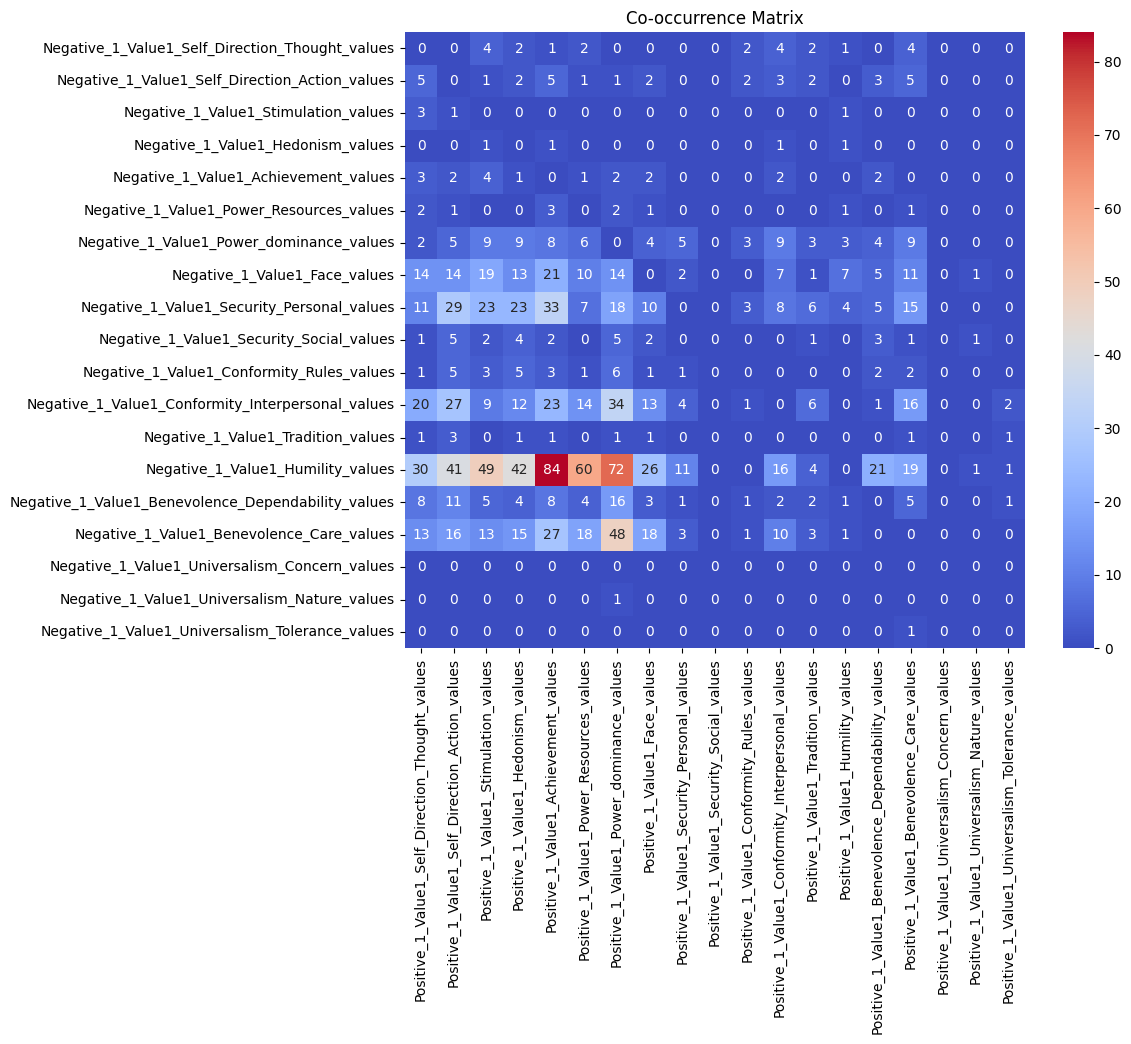

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
sns.heatmap(co_occurrence_df, annot=True, fmt=".0f", cmap="coolwarm")
plt.title("Co-occurrence Matrix")
plt.show()


Now lets do this for conditional co-occurences

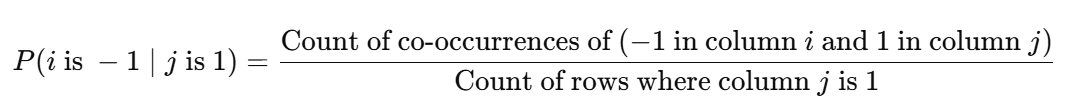

In [ ]:
# Initialize the conditional probability matrix
conditional_matrix = np.zeros((n, n))

# Compute conditional probabilities
for i in range(n):
    for j in range(n):
        if i != j:
            col_i = class_columns[i]
            col_j = class_columns[j]

            # Filter rows where col_j is 1
            rows_with_j_positive = (df[col_j] == 1).sum()

            if rows_with_j_positive > 0:
                # Count co-occurrences where col_i is -1 and col_j is 1
                count_neg_pos = ((df[col_i] == -1) & (df[col_j] == 1)).sum()

                # Calculate conditional probability
                conditional_matrix[i, j] = count_neg_pos / rows_with_j_positive
            else:
                # Handle division by zero
                conditional_matrix[i, j] = 0

# Convert to DataFrame for better readability
conditional_df = pd.DataFrame(conditional_matrix,
                              columns=[f"Given_Positive_{col}" for col in class_columns],
                              index=[f"Negative_{col}" for col in class_columns])

# Save or display the result

print(conditional_df)


                                                    Given_Positive_1_Value1_Self_Direction_Thought_values  \
Negative_1_Value1_Self_Direction_Thought_values                                              0.000000       
Negative_1_Value1_Self_Direction_Action_values                                               0.024038       
Negative_1_Value1_Stimulation_values                                                         0.014423       
Negative_1_Value1_Hedonism_values                                                            0.000000       
Negative_1_Value1_Achievement_values                                                         0.014423       
Negative_1_Value1_Power_Resources_values                                                     0.009615       
Negative_1_Value1_Power_dominance_values                                                     0.014423       
Negative_1_Value1_Face_values                                                                0.067308       
Negative_1_Value1_S

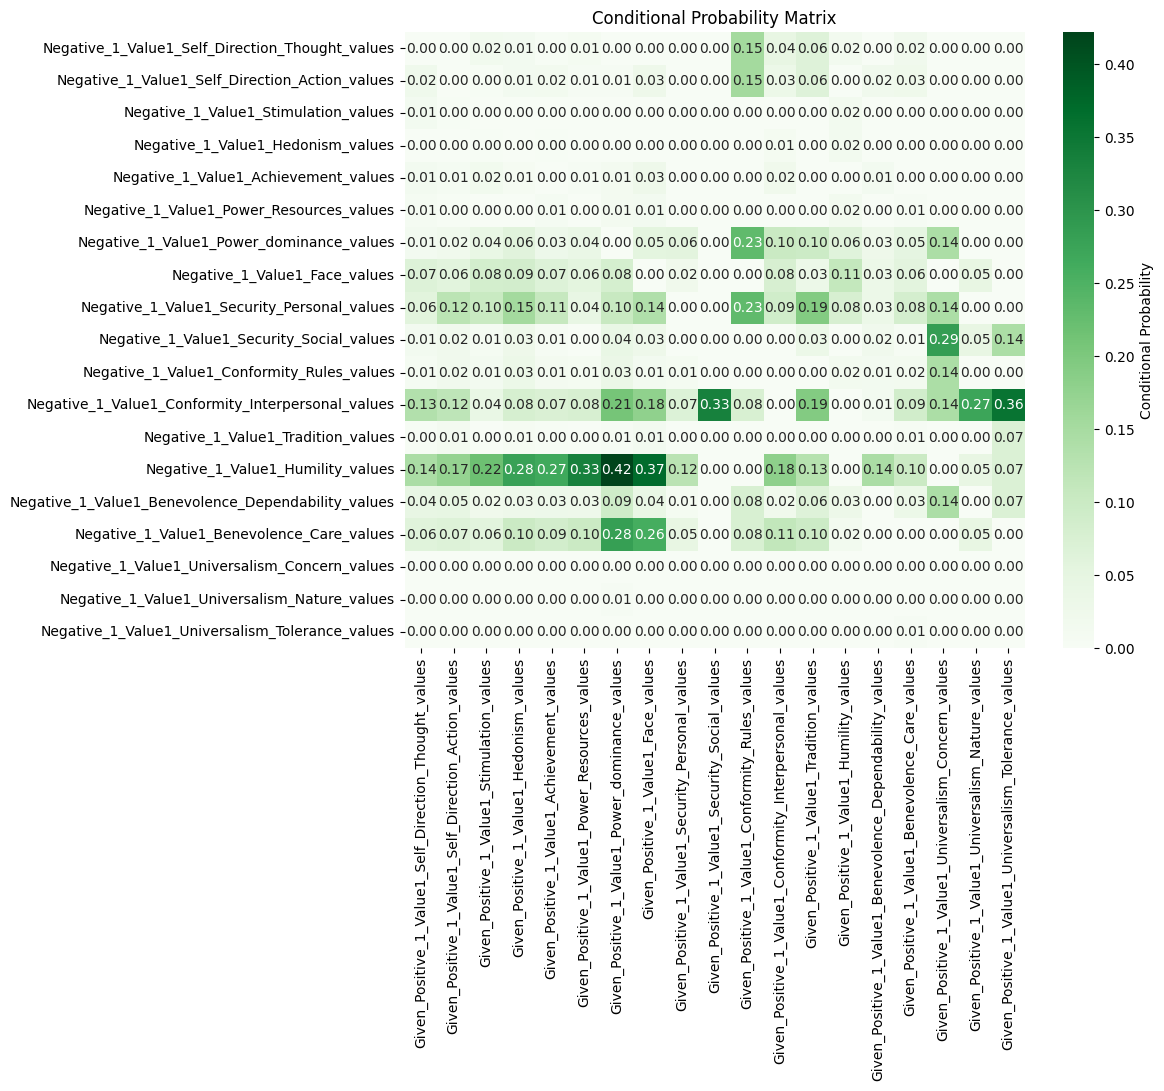

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
sns.heatmap(conditional_df, annot=True, fmt=".2f", cmap="Greens", cbar_kws={'label': 'Conditional Probability'})
plt.title("Conditional Probability Matrix")
plt.show()


now lets go for PMI:

In [ ]:
import numpy as np
import pandas as pd
import math

# Initialize the PMI matrix
pmi_matrix = np.zeros((n, n))

# Total number of rows
total_rows = len(df)

# Compute PMI
for i in range(n):
    for j in range(n):
        if i != j:
            col_i = class_columns[i]
            col_j = class_columns[j]

            # Joint probability: P(i = -1 and j = 1)
            joint_count = ((df[col_i] == -1) & (df[col_j] == 1)).sum()
            joint_prob = joint_count / total_rows

            # Marginal probabilities
            prob_i_neg = (df[col_i] == -1).sum() / total_rows
            prob_j_pos = (df[col_j] == 1).sum() / total_rows

            # Calculate PMI
            if joint_prob > 0 and prob_i_neg > 0 and prob_j_pos > 0:
                pmi_matrix[i, j] = math.log(joint_prob / (prob_i_neg * prob_j_pos))
            else:
                # Handle cases with zero probabilities
                pmi_matrix[i, j] = 0

# Convert to DataFrame for better readability
pmi_df = pd.DataFrame(pmi_matrix,
                      columns=[f"Positive_{col}" for col in class_columns],
                      index=[f"Negative_{col}" for col in class_columns])

# display the result

print(pmi_df)


                                                    Positive_1_Value1_Self_Direction_Thought_values  \
Negative_1_Value1_Self_Direction_Thought_values                                            0.000000   
Negative_1_Value1_Self_Direction_Action_values                                            -0.118264   
Negative_1_Value1_Stimulation_values                                                       1.491174   
Negative_1_Value1_Hedonism_values                                                          0.000000   
Negative_1_Value1_Achievement_values                                                      -0.354653   
Negative_1_Value1_Power_Resources_values                                                  -0.012903   
Negative_1_Value1_Power_dominance_values                                                  -1.216876   
Negative_1_Value1_Face_values                                                             -0.358405   
Negative_1_Value1_Security_Personal_values                               

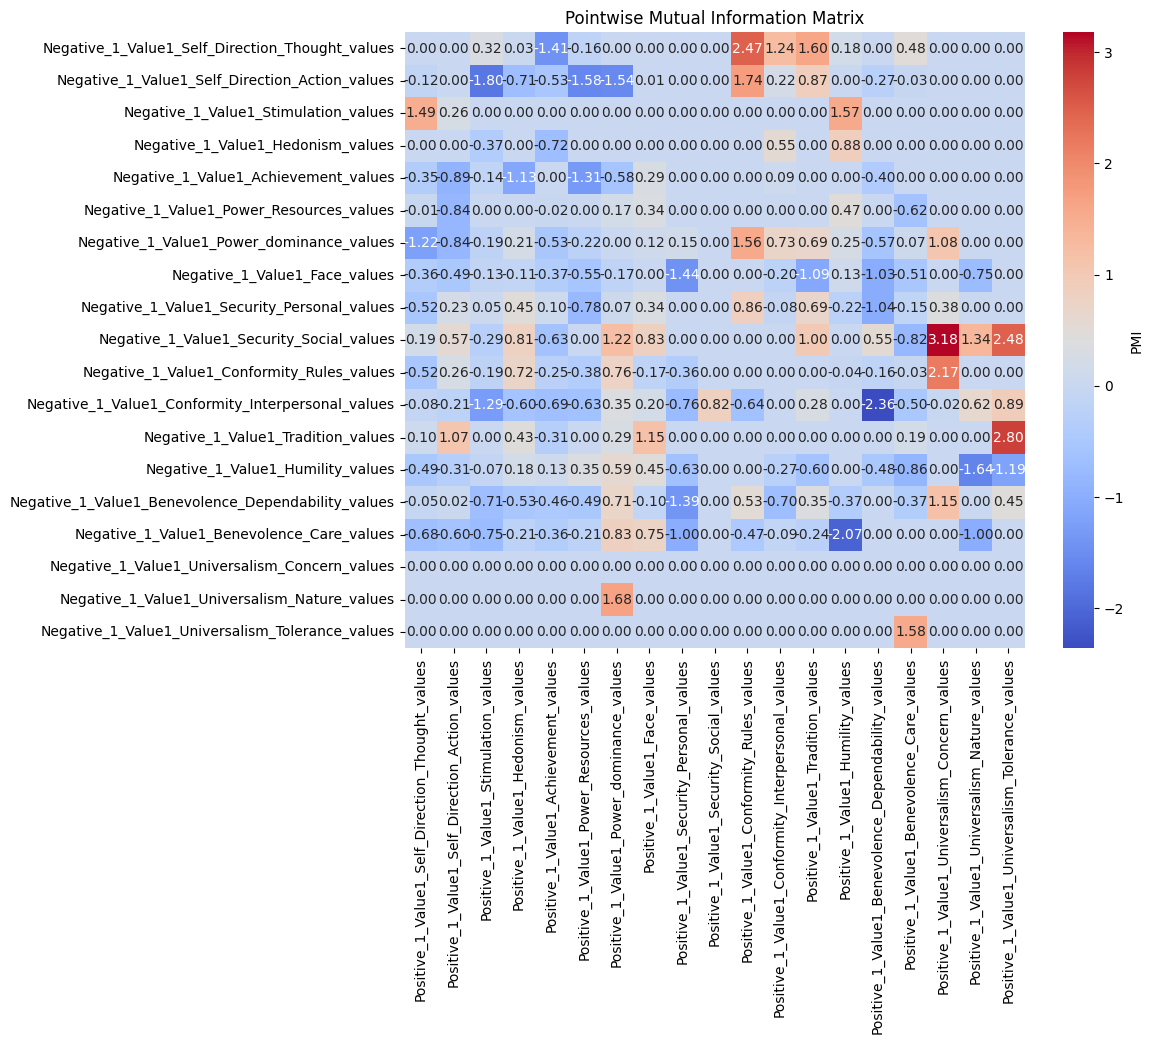

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
sns.heatmap(pmi_df, annot=True, fmt=".2f", cmap="coolwarm", cbar_kws={'label': 'PMI'})
plt.title("Pointwise Mutual Information Matrix")
plt.show()


REMEMBER:

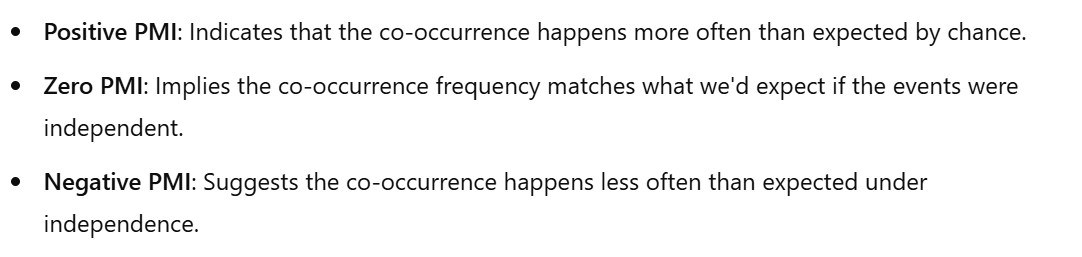